In [1]:
import pandas as pd
import matplotlib.pyplot as plt

In [4]:
df = pd.read_csv("../data/cleaned/customer_churn_cleaned.csv")

In [3]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [5]:
print("Average Monthly Charges:")
print(df["MonthlyCharges"].mean())

Average Monthly Charges:
64.76169246059918


In [6]:
print("Average Monthly Charges by Churn:")
print(df.groupby("Churn")["MonthlyCharges"].mean())

Average Monthly Charges by Churn:
Churn
No     61.265124
Yes    74.441332
Name: MonthlyCharges, dtype: float64


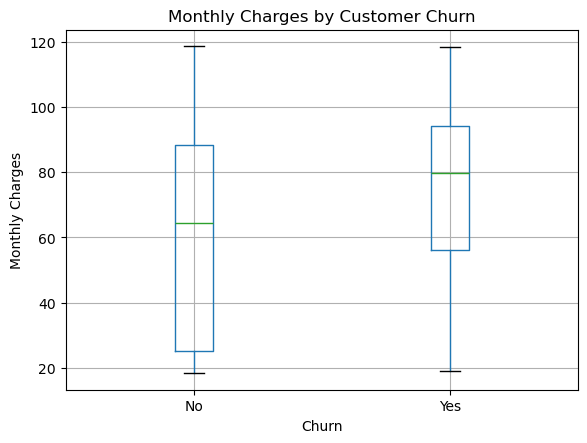

In [7]:
df.boxplot(column="MonthlyCharges", by="Churn")

plt.title("Monthly Charges by Customer Churn")
plt.suptitle("")
plt.xlabel("Churn")
plt.ylabel("Monthly Charges")
plt.show()

In [8]:
print("Average Total Charges:")
print(df["TotalCharges"].mean())

Average Total Charges:
2279.7343035638223


In [9]:
print("Average Total Charges by Churn:")
print(df.groupby("Churn")["TotalCharges"].mean())

Average Total Charges by Churn:
Churn
No     2549.911442
Yes    1531.796094
Name: TotalCharges, dtype: float64


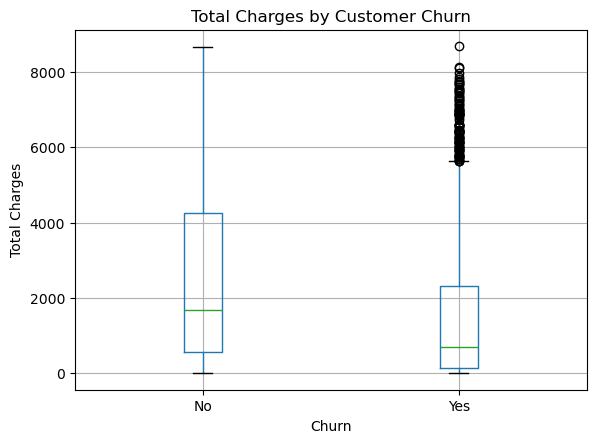

In [10]:
df.boxplot(column="TotalCharges", by="Churn")

plt.title("Total Charges by Customer Churn")
plt.suptitle("")
plt.xlabel("Churn")
plt.ylabel("Total Charges")
plt.show()

In [11]:
charges_summary = df.groupby("Churn").agg(
    Customer_Count=("Churn", "count"),
    Average_Monthly_Charges=("MonthlyCharges", "mean"),
    Average_Total_Charges=("TotalCharges", "mean")
).reset_index()

In [12]:
charges_summary.to_csv(
    "../results/charges_analysis_summary.csv",
    index=False
)

In [13]:
charges_summary

,Churn,Customer_Count,Average_Monthly_Charges,Average_Total_Charges
0,No,5174,61.265124,2549.911442
1,Yes,1869,74.441332,1531.796094
